In [1]:
# Install packages
!pip install -q kaggle torch torchvision timm
!pip install -q matplotlib seaborn scikit-learn pillow
print(" Packages installed!")

 Packages installed!


In [5]:
# Kaggle credentials are read from the environment, never stored in the notebook.
# Set KAGGLE_USERNAME and KAGGLE_KEY before running this cell.
import os
assert os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'), 'Set Kaggle credentials in the environment'
!kaggle datasets list --search "skin lesion" 2>&1 | head -5


In [6]:
# Download HAM10000 — perfect size for Colab
!kaggle datasets download -d surajghuwalewala/ham1000-segmentation-and-classification
!unzip -q ham1000-segmentation-and-classification.zip -d skin_data
print("Dataset downloaded!")
!ls skin_data/

Dataset URL: https://www.kaggle.com/datasets/surajghuwalewala/ham1000-segmentation-and-classification
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 2.59G/2.59G [00:34<00:00, 79.5MB/s]

Dataset downloaded!
GroundTruth.csv  images  masks


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os

# Load ground truth
df = pd.read_csv('skin_data/GroundTruth.csv')
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst few rows:")
df.head()

Dataset shape: (10015, 8)

Columns: ['image', 'MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

First few rows:


,image,MEL,NV,BCC,AKIEC,BKL,DF,VASC
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0


 Labels created!

Class distribution:
label_name
Melanocytic Nevi        6705
Melanoma                1113
Benign Keratosis        1099
Basal Cell Carcinoma     514
Actinic Keratosis        327
Vascular Lesion          142
Dermatofibroma           115
Name: count, dtype: int64


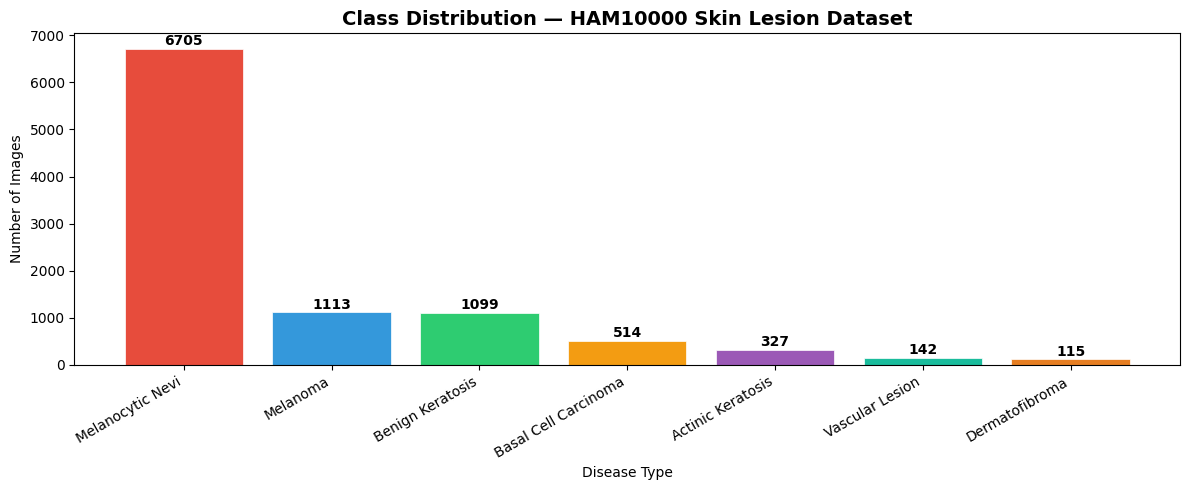


Total images: 10015
Most common : Melanocytic Nevi (6705 images)
Rarest      : Dermatofibroma (115 images)


In [8]:
# Convert one-hot to class labels
class_names = {
    'MEL':   'Melanoma',
    'NV':    'Melanocytic Nevi',
    'BCC':   'Basal Cell Carcinoma',
    'AKIEC': 'Actinic Keratosis',
    'BKL':   'Benign Keratosis',
    'DF':    'Dermatofibroma',
    'VASC':  'Vascular Lesion'
}

class_cols = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

# Get label for each image
df['label']      = df[class_cols].idxmax(axis=1)
df['label_name'] = df['label'].map(class_names)
df['label_idx']  = df['label'].map({c: i for i, c in enumerate(class_cols)})

print(" Labels created!")
print(f"\nClass distribution:")
print(df['label_name'].value_counts())

# Plot class distribution
plt.figure(figsize=(12, 5))
counts = df['label_name'].value_counts()
colors = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22']
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor='white', linewidth=0.5)
plt.title('Class Distribution — HAM10000 Skin Lesion Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Disease Type')
plt.ylabel('Number of Images')
plt.xticks(rotation=30, ha='right')
for bar, count in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 20,
             str(count), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nTotal images: {len(df)}")
print(f"Most common : {counts.index[0]} ({counts.values[0]} images)")
print(f"Rarest      : {counts.index[-1]} ({counts.values[-1]} images)")

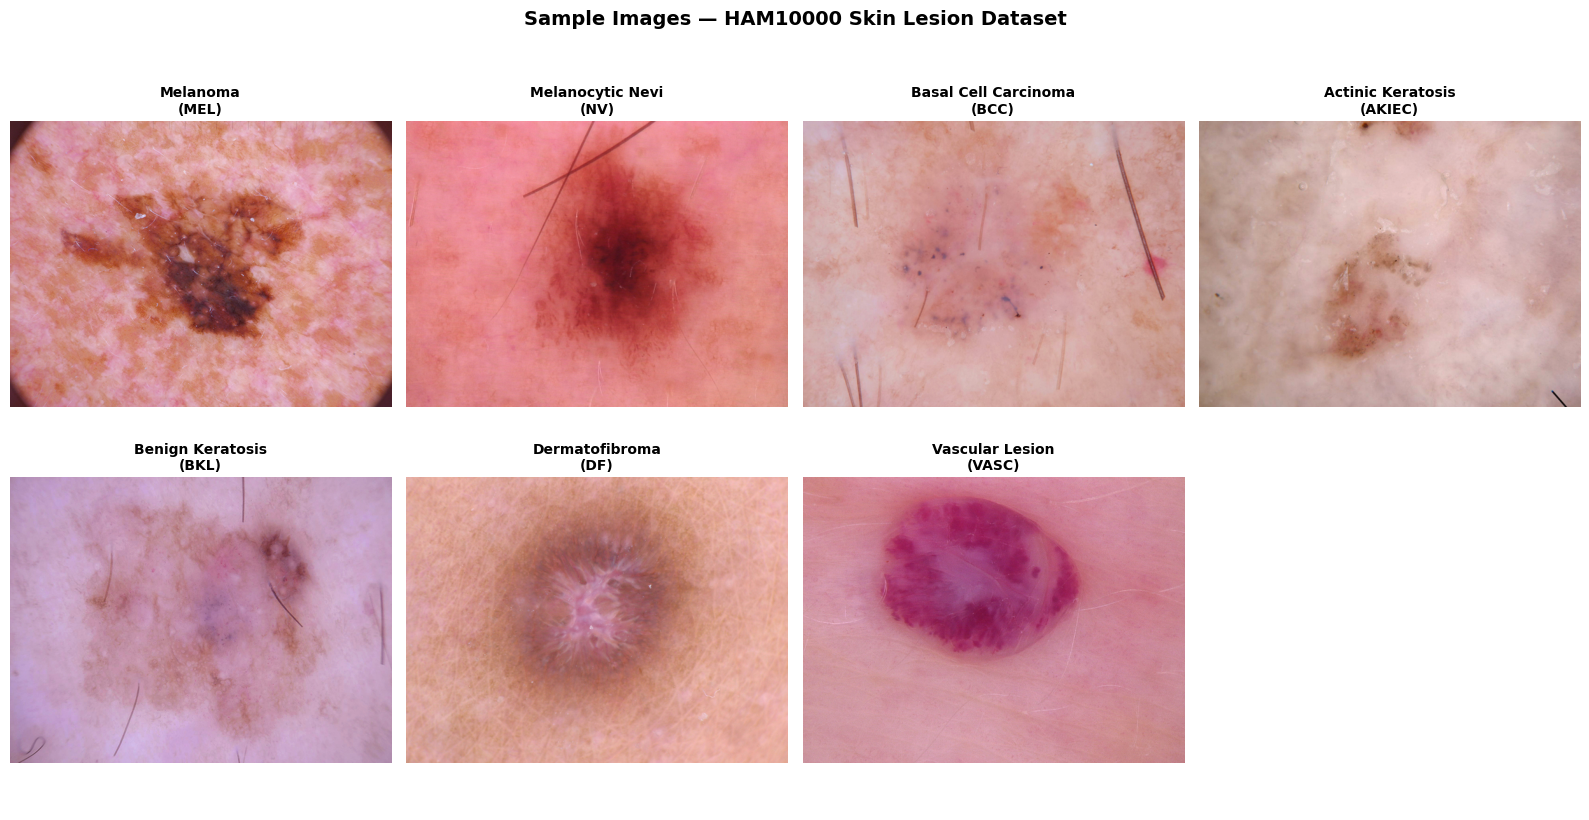

 Sample images displayed!


In [9]:
# Show sample images from each class
img_dir = 'skin_data/images'

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (code, name) in enumerate(class_names.items()):
    sample = df[df['label'] == code].iloc[0]
    img_path = os.path.join(img_dir, sample['image'] + '.jpg')

    try:
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"{name}\n({code})", fontsize=10, fontweight='bold')
        axes[i].axis('off')
    except:
        axes[i].text(0.5, 0.5, 'Image not found', ha='center')
        axes[i].axis('off')

# Hide last empty subplot
axes[-1].axis('off')

plt.suptitle('Sample Images — HAM10000 Skin Lesion Dataset',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Sample images displayed!")

In [10]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np

# ── Train/Val/Test Split ───────────────────────────────────────
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
val_df,   test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])

print(f"Train : {len(train_df)} images")
print(f"Val   : {len(val_df)} images")
print(f"Test  : {len(test_df)} images")

# ── Class Weights for Imbalance ────────────────────────────────
class_counts  = train_df['label_idx'].value_counts().sort_index().values
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum() * len(class_cols)
class_weights = torch.FloatTensor(class_weights)
print(f"\nClass weights: {class_weights.numpy().round(3)}")

# ── Transforms ─────────────────────────────────────────────────
IMG_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ── Custom Dataset ─────────────────────────────────────────────
class SkinDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.img_dir   = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row      = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['image'] + '.jpg')
        image    = Image.open(img_path).convert('RGB')
        label    = int(row['label_idx'])
        if self.transform:
            image = self.transform(image)
        return image, label

# ── DataLoaders ────────────────────────────────────────────────
img_dir     = 'skin_data/images'
BATCH_SIZE  = 32

train_dataset = SkinDataset(train_df, img_dir, train_transforms)
val_dataset   = SkinDataset(val_df,   img_dir, val_transforms)
test_dataset  = SkinDataset(test_df,  img_dir, val_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\n DataLoaders ready!")
print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")

# Verify one batch
images, labels = next(iter(train_loader))
print(f"\nBatch shape : {images.shape}")
print(f"Label shape : {labels.shape}")

Train : 8012 images
Val   : 1001 images
Test  : 1002 images

Class weights: [0.278 0.046 0.601 0.943 0.281 2.685 2.167]

 DataLoaders ready!
Train batches : 251
Val batches   : 32
Test batches  : 32

Batch shape : torch.Size([32, 3, 224, 224])
Label shape : torch.Size([32])


In [11]:
import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

# ── Load pretrained EfficientNet ───────────────────────────────
model = models.efficientnet_b0(weights='IMAGENET1K_V1')

# Freeze all layers first
for param in model.parameters():
    param.requires_grad = False

# Replace classifier head for 7 classes
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(model.classifier[1].in_features, 256),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(256, 7)
)

# Unfreeze last 3 blocks for fine-tuning
for param in model.features[-3:].parameters():
    param.requires_grad = True

model = model.to(device)

# Count parameters
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n EfficientNetB0 loaded!")
print(f"Total parameters     : {total:,}")
print(f"Trainable parameters : {trainable:,}")
print(f"Frozen parameters    : {total - trainable:,}")
print(f"Trainable %          : {trainable/total*100:.2f}%")

Training on: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 109MB/s] 



 EfficientNetB0 loaded!
Total parameters     : 4,337,283
Trainable parameters : 3,485,475
Frozen parameters    : 851,808
Trainable %          : 80.36%


In [12]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

# ── Loss, Optimizer, Scheduler ─────────────────────────────────
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = CosineAnnealingLR(optimizer, T_max=10, eta_min=1e-6)

# ── Training Function ──────────────────────────────────────────
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total   += labels.size(0)
    return total_loss / len(loader), correct / total

# ── Validation Function ────────────────────────────────────────
def val_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total   += labels.size(0)
    return total_loss / len(loader), correct / total

print(" Training setup ready!")
print(f"Loss     : CrossEntropyLoss with class weights")
print(f"Optimizer: AdamW (lr=1e-3, weight_decay=1e-4)")
print(f"Scheduler: CosineAnnealingLR (T_max=10)")

 Training setup ready!
Loss     : CrossEntropyLoss with class weights
Optimizer: AdamW (lr=1e-3, weight_decay=1e-4)
Scheduler: CosineAnnealingLR (T_max=10)


In [13]:
# ── Training Loop ──────────────────────────────────────────────
EPOCHS = 10
best_val_acc  = 0
best_val_loss = float('inf')
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print(" Starting training...")
print(f"Epochs: {EPOCHS} | Batch size: {BATCH_SIZE} | Device: {device}")
print("=" * 70)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss,   val_acc   = val_epoch(model, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc  = val_acc
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_skin_model.pth")
        flag = " BEST"
    else:
        flag = ""

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% {flag}")

print("=" * 70)
print(f"\n Best Val Accuracy : {best_val_acc*100:.2f}%")
print(f" Best Val Loss     : {best_val_loss:.4f}")
print("\n Training complete!")

 Starting training...
Epochs: 10 | Batch size: 32 | Device: cuda
Epoch [01/10] Train Loss: 1.3457 | Train Acc: 54.27% | Val Loss: 1.1155 | Val Acc: 57.44%  BEST
Epoch [02/10] Train Loss: 1.0716 | Train Acc: 63.78% | Val Loss: 1.0089 | Val Acc: 55.24% 
Epoch [03/10] Train Loss: 0.9193 | Train Acc: 64.87% | Val Loss: 0.9469 | Val Acc: 66.23%  BEST
Epoch [04/10] Train Loss: 0.7991 | Train Acc: 67.47% | Val Loss: 0.8385 | Val Acc: 69.03%  BEST
Epoch [05/10] Train Loss: 0.7124 | Train Acc: 71.97% | Val Loss: 0.7908 | Val Acc: 73.73%  BEST
Epoch [06/10] Train Loss: 0.5998 | Train Acc: 74.31% | Val Loss: 0.8239 | Val Acc: 68.43% 
Epoch [07/10] Train Loss: 0.5286 | Train Acc: 76.73% | Val Loss: 0.8297 | Val Acc: 72.63% 
Epoch [08/10] Train Loss: 0.4817 | Train Acc: 77.18% | Val Loss: 0.7369 | Val Acc: 74.33%  BEST
Epoch [09/10] Train Loss: 0.4161 | Train Acc: 80.23% | Val Loss: 0.7494 | Val Acc: 75.02%  BEST
Epoch [10/10] Train Loss: 0.3844 | Train Acc: 80.57% | Val Loss: 0.7293 | Val Acc: 75.

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Load best model
model.load_state_dict(torch.load("best_skin_model.pth"))
model.eval()

# Run on test set
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs   = torch.softmax(outputs, dim=1)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

# Classification report
label_names = list(class_names.values())
print("=" * 60)
print("       TEST SET EVALUATION RESULTS")
print("=" * 60)
print(classification_report(all_labels, all_preds, target_names=label_names))

# Overall accuracy
test_acc = (all_preds == all_labels).mean()
print(f"Overall Test Accuracy: {test_acc*100:.2f}%")

       TEST SET EVALUATION RESULTS
                      precision    recall  f1-score   support

            Melanoma       0.39      0.75      0.52       112
    Melanocytic Nevi       0.96      0.75      0.84       671
Basal Cell Carcinoma       0.69      0.71      0.70        52
   Actinic Keratosis       0.46      0.75      0.57        32
    Benign Keratosis       0.59      0.67      0.63       110
      Dermatofibroma       0.57      0.73      0.64        11
     Vascular Lesion       0.62      0.93      0.74        14

            accuracy                           0.74      1002
           macro avg       0.61      0.76      0.66      1002
        weighted avg       0.82      0.74      0.76      1002

Overall Test Accuracy: 74.15%


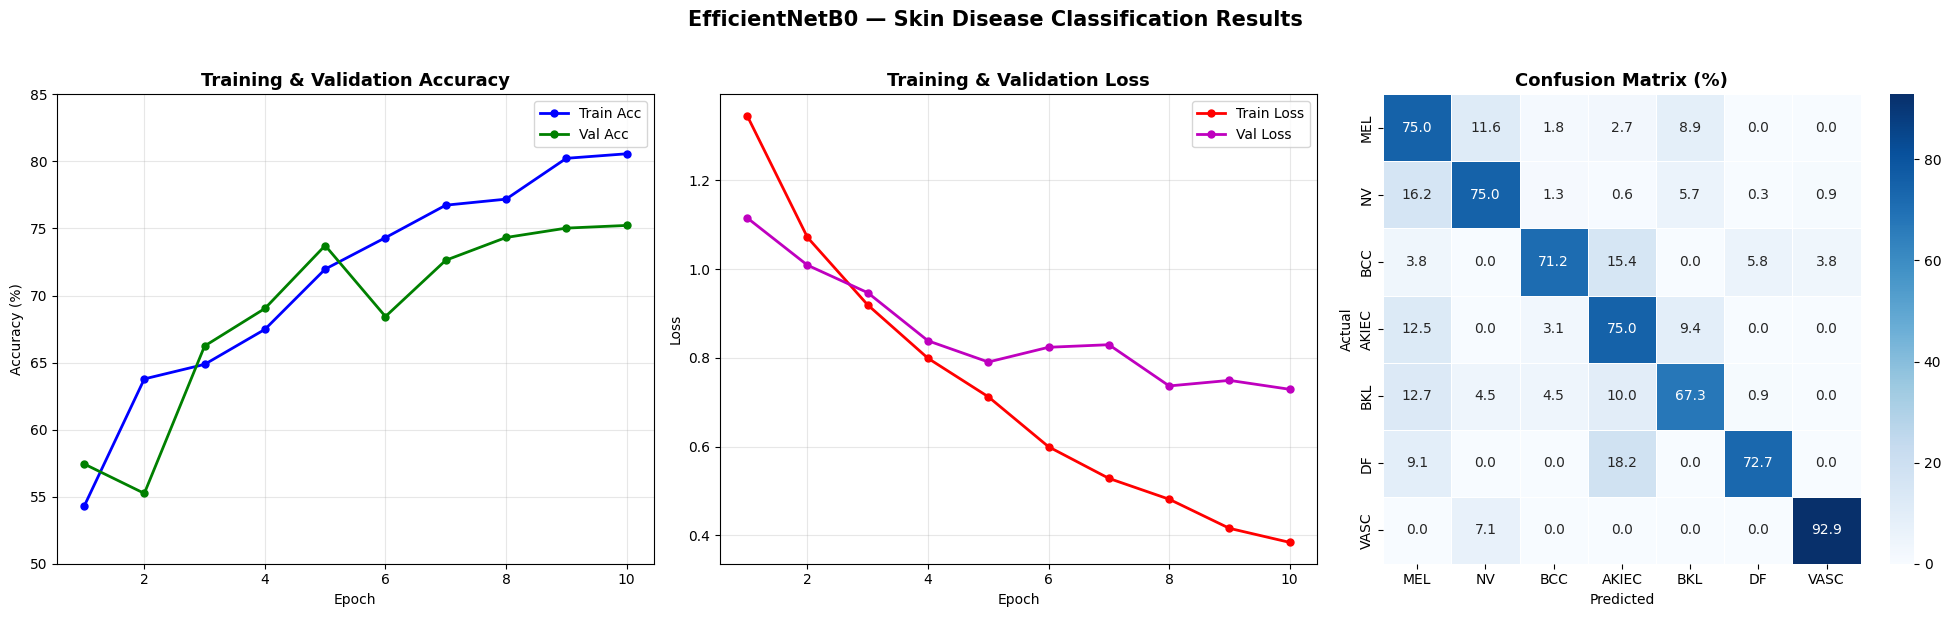

 Visualizations saved!


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ── Plot 1: Training Curves ────────────────────────────────────
axes[0].plot(range(1, EPOCHS+1), [x*100 for x in history['train_acc']],
             'b-o', label='Train Acc', linewidth=2, markersize=5)
axes[0].plot(range(1, EPOCHS+1), [x*100 for x in history['val_acc']],
             'g-o', label='Val Acc', linewidth=2, markersize=5)
axes[0].set_title('Training & Validation Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(50, 85)

# ── Plot 2: Loss Curves ────────────────────────────────────────
axes[1].plot(range(1, EPOCHS+1), history['train_loss'],
             'r-o', label='Train Loss', linewidth=2, markersize=5)
axes[1].plot(range(1, EPOCHS+1), history['val_loss'],
             'm-o', label='Val Loss', linewidth=2, markersize=5)
axes[1].set_title('Training & Validation Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ── Plot 3: Confusion Matrix ───────────────────────────────────
short_names = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']
cm = confusion_matrix(all_labels, all_preds)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=short_names, yticklabels=short_names,
            ax=axes[2], linewidths=0.5)
axes[2].set_title('Confusion Matrix (%)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.suptitle('EfficientNetB0 — Skin Disease Classification Results',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('training_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Visualizations saved!")

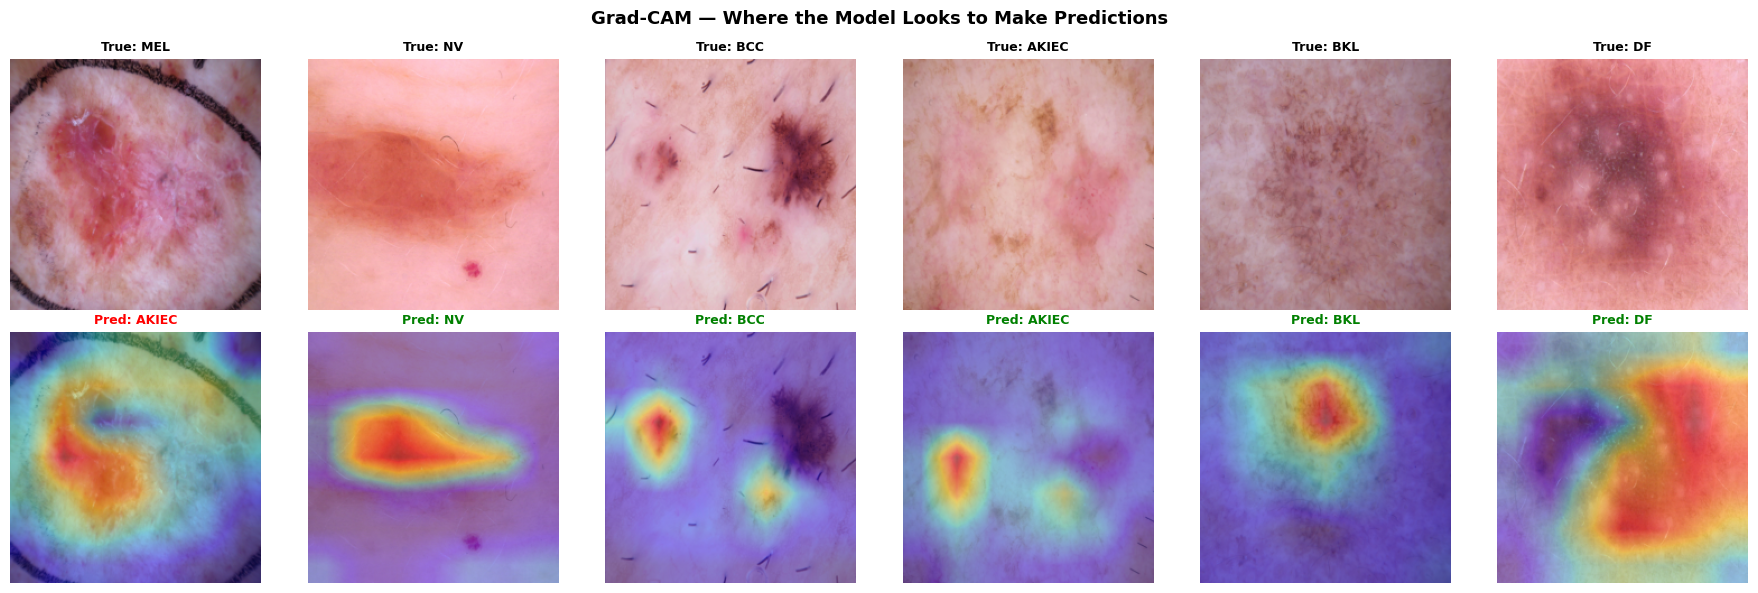

 Grad-CAM saved!


In [16]:
import torch.nn.functional as F

# ── Grad-CAM Implementation ────────────────────────────────────
class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        self.model.zero_grad()
        output[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam     = (weights * self.activations).sum(dim=1, keepdim=True)
        cam     = F.relu(cam)
        cam     = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
        cam     = cam.squeeze().cpu().numpy()
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx

# Initialize Grad-CAM on last conv layer
gradcam = GradCAM(model, model.features[-1])

# ── Visualize Grad-CAM on test samples ────────────────────────
import matplotlib.cm as cm

def show_gradcam(dataset, df_subset, num_samples=6):
    fig, axes = plt.subplots(2, num_samples, figsize=(18, 6))

    indices = []
    for cls in range(7):
        cls_indices = np.where(np.array(df_subset['label_idx'].values) == cls)[0]
        if len(cls_indices) > 0:
            indices.append(cls_indices[0])
        if len(indices) >= num_samples:
            break

    for col, idx in enumerate(indices[:num_samples]):
        img_tensor, label = dataset[idx]
        input_tensor = img_tensor.unsqueeze(0).to(device)
        input_tensor.requires_grad = True

        cam, pred_idx = gradcam.generate(input_tensor)

        # Original image
        img_np = img_tensor.permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)

        # Heatmap overlay
        heatmap = cm.jet(cam)[:, :, :3]
        overlay = 0.6 * img_np + 0.4 * heatmap

        axes[0, col].imshow(img_np)
        axes[0, col].set_title(f"True: {short_names[label]}", fontsize=9, fontweight='bold')
        axes[0, col].axis('off')

        axes[1, col].imshow(overlay)
        axes[1, col].set_title(f"Pred: {short_names[pred_idx]}", fontsize=9,
                               color='green' if pred_idx == label else 'red', fontweight='bold')
        axes[1, col].axis('off')

    axes[0, 0].set_ylabel("Original", fontsize=10, fontweight='bold')
    axes[1, 0].set_ylabel("Grad-CAM", fontsize=10, fontweight='bold')

    plt.suptitle("Grad-CAM — Where the Model Looks to Make Predictions",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('gradcam_visualization.png', dpi=150, bbox_inches='tight')
    plt.show()

show_gradcam(test_dataset, test_df)
print(" Grad-CAM saved!")

In [17]:
# Save all results
from google.colab import files

# Download key files
files.download('best_skin_model.pth')
files.download('training_results.png')
files.download('gradcam_visualization.png')
files.download('class_distribution.png')
files.download('sample_images.png')

print(" All files downloaded!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 All files downloaded!
